<a href="https://colab.research.google.com/github/inosven/Neural-Networks-Zero-to-Hero/blob/main/makemore_excercise2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import drive
drive.mount('/content/drive')
with open('/content/drive/MyDrive/Colab Notebooks/Zero2Hero_Karpathy/Data/names.txt','r') as f:
  text = f.read().splitlines()

Mounted at /content/drive


In [3]:
words = text

In [4]:
chars = sorted(list(set(''.join(words))))

In [5]:
stoi = {c:i+1 for i,c in enumerate(chars)}
stoi['.'] = 0
itos  = {i:s for s,i in stoi.items()}

In [6]:
import torch

In [7]:
block_size = 3
def build_dataset(words):
  X,Y = [],[]
  for w in words:
    context = [0] *  block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      context = context[1:] + [ix]
  X = torch.tensor(X)
  Y = torch.tensor(Y)
  return X,Y

In [8]:
import random
random.seed(42)
random.shuffle(words)
n = len(words)
n1 = int(n*0.8)
n2 = int(n*0.9)

In [9]:
Xtr,Ytr = build_dataset(words[:n1])
Xval,Yval = build_dataset(words[n1:n2])
Xte,Yte = build_dataset(words[n2:])


In [10]:
# MLP
n_emb = 10
n_hidden = 200
vocab_size = len(stoi)
g = torch.Generator().manual_seed(52123)
C = torch.randn((vocab_size, n_emb), generator=g)
W1 = torch.randn((n_emb * block_size, n_hidden), generator=g) * 5/3/(n_emb * block_size)**0.5
# b1 bn will cancel it
W2 =  torch.randn((n_hidden,vocab_size), generator=g) * 0.01
b2 = torch.randn(vocab_size, generator=g) * 0.01

bn_gain = torch.ones((1,n_hidden))
bn_bias = torch.zeros((1,n_hidden))

bnmean_running = torch.zeros((1,n_hidden))
bnstd_running = torch.ones((1,n_hidden))

parameters = [C,W1, W2, b2, bn_gain, bn_bias]

for p in parameters:
  p.requires_grad= True

print(sum(p.nelement() for p in parameters))


12097


In [11]:
import torch.nn.functional as F

In [12]:
max_steps = 200000
batch_size =50
lossi = []
for i in range(max_steps):
  # mini batch
  ix = torch.randint(0,Xtr.shape[0],(batch_size,),generator=g)
  Xb, Yb = Xtr[ix], Ytr[ix]

  #forward pass

  emb = C[Xb]
  embcat = emb.view(emb.shape[0],-1)
  hpreact = embcat @ W1
  bnmeani = hpreact.mean(0,keepdim=True)
  bnstdi = hpreact.std(0,keepdim=True)
  hpreact = bn_gain * (hpreact-bnmeani) / (bnstdi+0.0001) + bn_bias
  h = torch.tanh(hpreact)
  with torch.no_grad():
    bnmean_running = 0.99 * bnmean_running + 0.01 * bnmeani
    bnstd_running = 0.99 * bnstd_running + 0.01 * bnstdi


  logits = h @ W2 + b2
  loss= F.cross_entropy(logits,Yb)

  # backward pass
  for p in parameters:
    p.grad=None
  loss.backward()

  # update
  lr = 0.1 if i <=1e5 else 0.01
  for p in parameters:
    p.data += -lr * p.grad

  # track
  if i % 100000==0:
    print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
  lossi.append(loss.log10().item())



      0/ 200000: 3.3060
 100000/ 200000: 2.1283


In [13]:
from matplotlib import pyplot as plt
%matplotlib inline

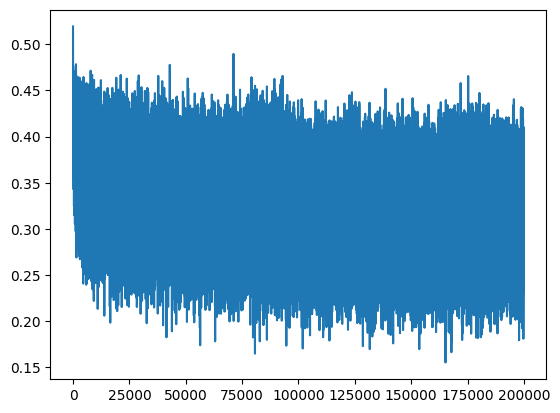

In [14]:
plt.plot(lossi)

In [15]:
@torch.no_grad
def split_loss(split):
  x,y = {
      'train': (Xtr,Ytr),
      'val' : (Xval,Yval),
      'test':(Xte,Yte)
  }[split]

  cmb = C[x]
  embcat = cmb.view(cmb.shape[0],-1)
  hpreact = embcat @ W1
  hpreact = bn_gain * (hpreact - bnmean_running) /(bnstd_running + 0.00001) + bn_bias
  h = torch.tanh(hpreact)
  logits = h @ W2+ b2
  loss = F.cross_entropy(logits,y)
  print(f'{split} loss: {loss:.4f}')

In [16]:
split_loss('train')
split_loss('val')


train loss: 2.0519
val loss: 2.1030


In [1]:
# prediction
for _ in range(20):
  context = [0] * block_size
  out = []

  emb = C[[context]]
  embcat = emb.view(emb.shape[0],-1)
  hpreact = embcat * W1
  hpreact = bn_gain * (hpreact-bnmean_running)/(bnstd_running+0.00001) +bn_bias
  h = torch.tanh(hpreact)
  logits = h @ W2 +b2
  probs = F.softmax(logits,dim=1)
  # sampling
  while True:
    ix = torch.multinomial(probs,num_samples=1)

    out.append(ix)
    context = context[1:]+[ix]
    if ix ==0:
      break
  print(''.join(itos[i] for i in out))



NameError: name 'block_size' is not defined